In [ ]:
print("Hello World")

Hello World


In [ ]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices('GPU'))


TensorFlow version: 2.21.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow:", tf.__version__)

(ds_train, ds_val, ds_test), info = tfds.load(
    "plant_village",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Number of classes:", info.features["label"].num_classes)
print("Class names:", info.features["label"].names)


TensorFlow: 2.21.0


ModuleNotFoundError: No module named 'importlib_resources'

In [ ]:

%pip install -q importlib-resources


In [ ]:

import tensorflow as tf
import tensorflow_datasets as tfds

(ds_train, ds_val, ds_test), info = tfds.load(
    "plant_village",
    split=["train[:70%]", "train[70%:85%]", "train[85%:]"],
    as_supervised=True,
    with_info=True
)

print("Dataset loaded successfully!")
print("Number of classes:", info.features["label"].num_classes)
print("Class names:", info.features["label"].names)


Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/1 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/plant_village/incomplete.YRROTQ_1.0.2/plant_village-train.tfrecord-[0-9][0…

Dataset plant_village downloaded and prepared to /root/tensorflow_datasets/plant_village/1.0.2. Subsequent calls will reuse this data.
Dataset loaded successfully!
Number of classes: 38
Class names: ['Apple___Apple_scab', 'Apple___Black_rot', 'Apple___Cedar_apple_rust', 'Apple___healthy', 'Blueberry___healthy', 'Cherry___healthy', 'Cherry___Powdery_mildew', 'Corn___Cercospora_leaf_spot Gray_leaf_spot', 'Corn___Common_rust', 'Corn___healthy', 'Corn___Northern_Leaf_Blight', 'Grape___Black_rot', 'Grape___Esca_(Black_Measles)', 'Grape___healthy', 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)', 'Orange___Haunglongbing_(Citrus_greening)', 'Peach___Bacterial_spot', 'Peach___healthy', 'Pepper,_bell___Bacterial_spot', 'Pepper,_bell___healthy', 'Potato___Early_blight', 'Potato___healthy', 'Potato___Late_blight', 'Raspberry___healthy', 'Soybean___healthy', 'Squash___Powdery_mildew', 'Strawberry___healthy', 'Strawberry___Leaf_scorch', 'Tomato___Bacterial_spot', 'Tomato___Early_blight', 'Tomato___hea

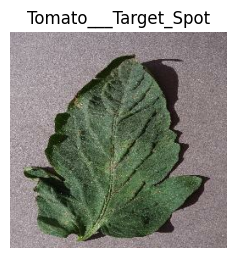

In [ ]:

import matplotlib.pyplot as plt

class_names = info.features["label"].names

plt.figure(figsize=(10, 5))

for images, labels in ds_train.take(1):
    for i in range(6):
        ax = plt.subplot(2, 3, i + 1)
        plt.imshow(images.numpy())
        plt.title(class_names[labels.numpy()])
        plt.axis("off")
        break

plt.tight_layout()
plt.show()


In [ ]:

import tensorflow as tf
from tensorflow.keras import layers, models

IMG_SIZE = 224
BATCH_SIZE = 32
NUM_CLASSES = info.features["label"].num_classes

def preprocess(image, label):
    image = tf.image.resize(image, (IMG_SIZE, IMG_SIZE))
    image = tf.cast(image, tf.float32)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image, label

train_data = (
    ds_train
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

val_data = (
    ds_val
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

test_data = (
    ds_test
    .map(preprocess, num_parallel_calls=tf.data.AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(tf.data.AUTOTUNE)
)

base_model = tf.keras.applications.MobileNetV2(
    input_shape=(IMG_SIZE, IMG_SIZE, 3),
    include_top=False,
    weights="imagenet"
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.2),
    layers.Dense(NUM_CLASSES, activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 38)             │        48,678 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,306,662 (8.80 MB)

 Trainable params: 48,678 (190.15 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=2,
        restore_best_weights=True
    )
]

history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=5,
    callbacks=callbacks
)


Epoch 1/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 82s 57ms/step - accuracy: 0.8698 - loss: 0.4813 - val_accuracy: 0.9322 - val_loss: 0.2192
Epoch 2/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 55s 46ms/step - accuracy: 0.9431 - loss: 0.1872 - val_accuracy: 0.9473 - val_loss: 0.1649
Epoch 3/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 56s 46ms/step - accuracy: 0.9532 - loss: 0.1458 - val_accuracy: 0.9488 - val_loss: 0.1581
Epoch 4/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 58s 48ms/step - accuracy: 0.9617 - loss: 0.1241 - val_accuracy: 0.9568 - val_loss: 0.1394
Epoch 5/5
1188/1188 ━━━━━━━━━━━━━━━━━━━━ 80s 46ms/step - accuracy: 0.9636 - loss: 0.1125 - val_accuracy: 0.9507 - val_loss: 0.1425


In [ ]:

test_loss, test_accuracy = model.evaluate(test_data, verbose=1)

print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")


255/255 ━━━━━━━━━━━━━━━━━━━━ 8s 33ms/step - accuracy: 0.9590 - loss: 0.1304
Test Accuracy: 95.90%
Test Loss: 0.1304


In [12]:

model.save("crop_disease_model.keras")

print("Model saved successfully!")


Model saved successfully!


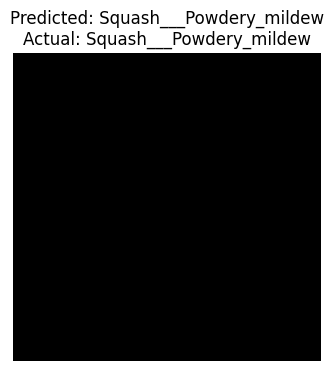

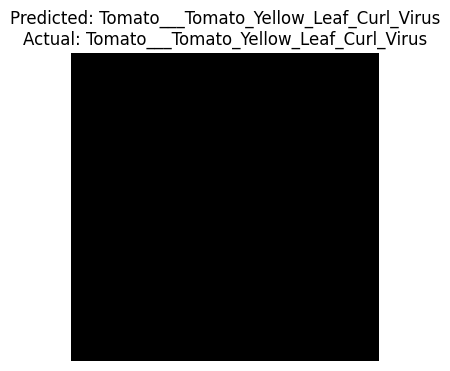

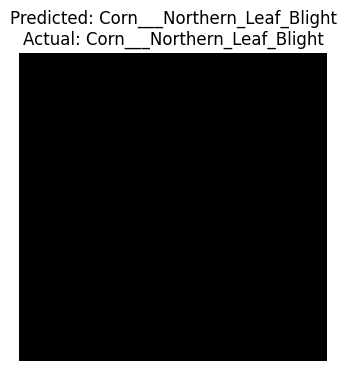

In [13]:

import matplotlib.pyplot as plt
import numpy as np

for images, labels in test_data.take(1):
    predictions = model.predict(images, verbose=0)

    for i in range(3):
        predicted_index = np.argmax(predictions[i])
        actual_index = labels[i].numpy()

        plt.figure(figsize=(4, 4))
        plt.imshow(
            tf.keras.applications.mobilenet_v2
            .preprocess_input(images[i].numpy()) * 0.5 + 0.5
        )
        plt.title(
            f"Predicted: {class_names[predicted_index]}\n"
            f"Actual: {class_names[actual_index]}"
        )
        plt.axis("off")
        plt.show()


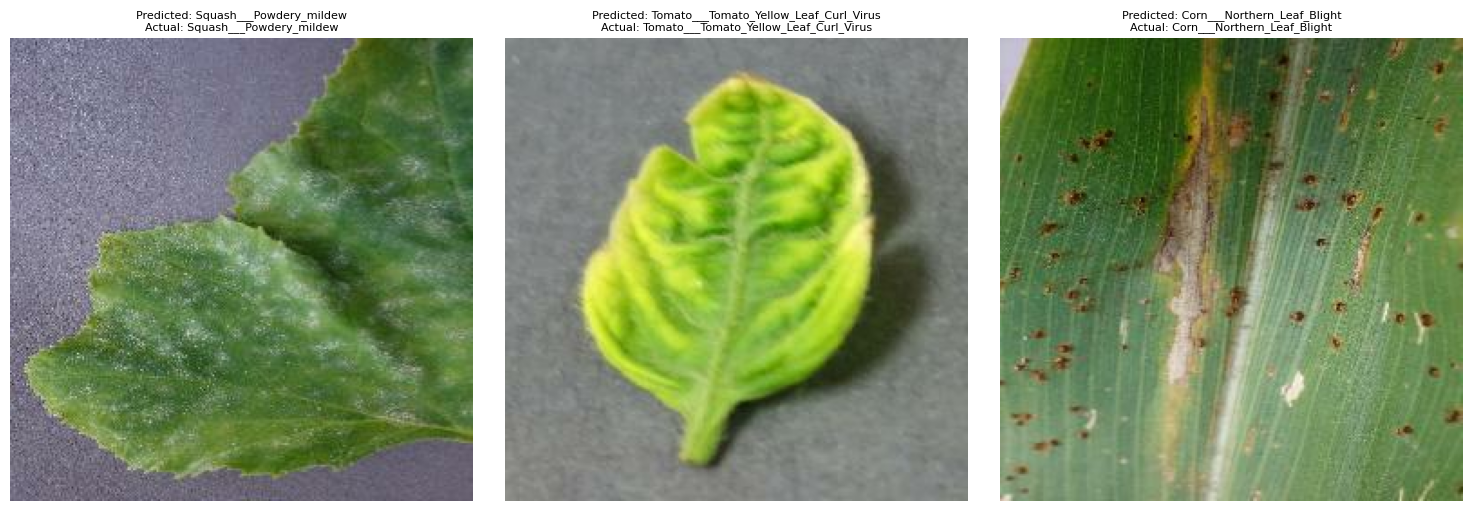

In [14]:

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

plt.figure(figsize=(15, 5))

for i, (image, label) in enumerate(ds_test.take(3)):
    # Original image ko display karna
    plt.subplot(1, 3, i + 1)
    plt.imshow(image.numpy())

    # Model ke liye image preprocess karna
    resized = tf.image.resize(image, (224, 224))
    processed = tf.keras.applications.mobilenet_v2.preprocess_input(
        tf.cast(resized, tf.float32)
    )

    # Prediction
    prediction = model.predict(
        tf.expand_dims(processed, axis=0), verbose=0
    )
    predicted_index = np.argmax(prediction[0])

    actual_index = label.numpy()

    plt.title(
        f"Predicted: {class_names[predicted_index]}\n"
        f"Actual: {class_names[actual_index]}",
        fontsize=8
    )
    plt.axis("off")

plt.tight_layout()
plt.show()


In [15]:

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

for images, labels in test_data.take(1):
    predictions = model.predict(images, verbose=0)

    for i in range(5):
        predicted_index = np.argmax(predictions[i])
        actual_index = labels[i].numpy()
        confidence = predictions[i][predicted_index] * 100

        print("Image:", i + 1)
        print("Predicted:", class_names[predicted_index])
        print("Actual:", class_names[actual_index])
        print(f"Confidence: {confidence:.2f}%")
        print("Correct:", predicted_index == actual_index)
        print("-" * 40)


Image: 1
Predicted: Squash___Powdery_mildew
Actual: Squash___Powdery_mildew
Confidence: 97.77%
Correct: True
----------------------------------------
Image: 2
Predicted: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Actual: Tomato___Tomato_Yellow_Leaf_Curl_Virus
Confidence: 100.00%
Correct: True
----------------------------------------
Image: 3
Predicted: Corn___Northern_Leaf_Blight
Actual: Corn___Northern_Leaf_Blight
Confidence: 59.12%
Correct: True
----------------------------------------
Image: 4
Predicted: Tomato___Spider_mites Two-spotted_spider_mite
Actual: Tomato___Spider_mites Two-spotted_spider_mite
Confidence: 95.62%
Correct: True
----------------------------------------
Image: 5
Predicted: Corn___healthy
Actual: Corn___healthy
Confidence: 100.00%
Correct: True
----------------------------------------


In [16]:

from sklearn.metrics import classification_report
import numpy as np

y_true = []
y_pred = []

for images, labels in test_data:
    predictions = model.predict(images, verbose=0)
    y_true.extend(labels.numpy())
    y_pred.extend(np.argmax(predictions, axis=1))

print(classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0,
    digits=3
))


                                               precision    recall  f1-score   support

                           Apple___Apple_scab      0.978     0.917     0.946        96
                            Apple___Black_rot      1.000     0.963     0.981       107
                     Apple___Cedar_apple_rust      0.976     1.000     0.988        40
                              Apple___healthy      0.962     0.996     0.979       255
                          Blueberry___healthy      0.991     1.000     0.995       213
                             Cherry___healthy      1.000     0.993     0.996       135
                      Cherry___Powdery_mildew      0.993     0.993     0.993       147
   Corn___Cercospora_leaf_spot Gray_leaf_spot      0.875     0.733     0.797        86
                           Corn___Common_rust      0.989     1.000     0.995       185
                               Corn___healthy      1.000     1.000     1.000       167
                  Corn___Northern_Leaf_Bli

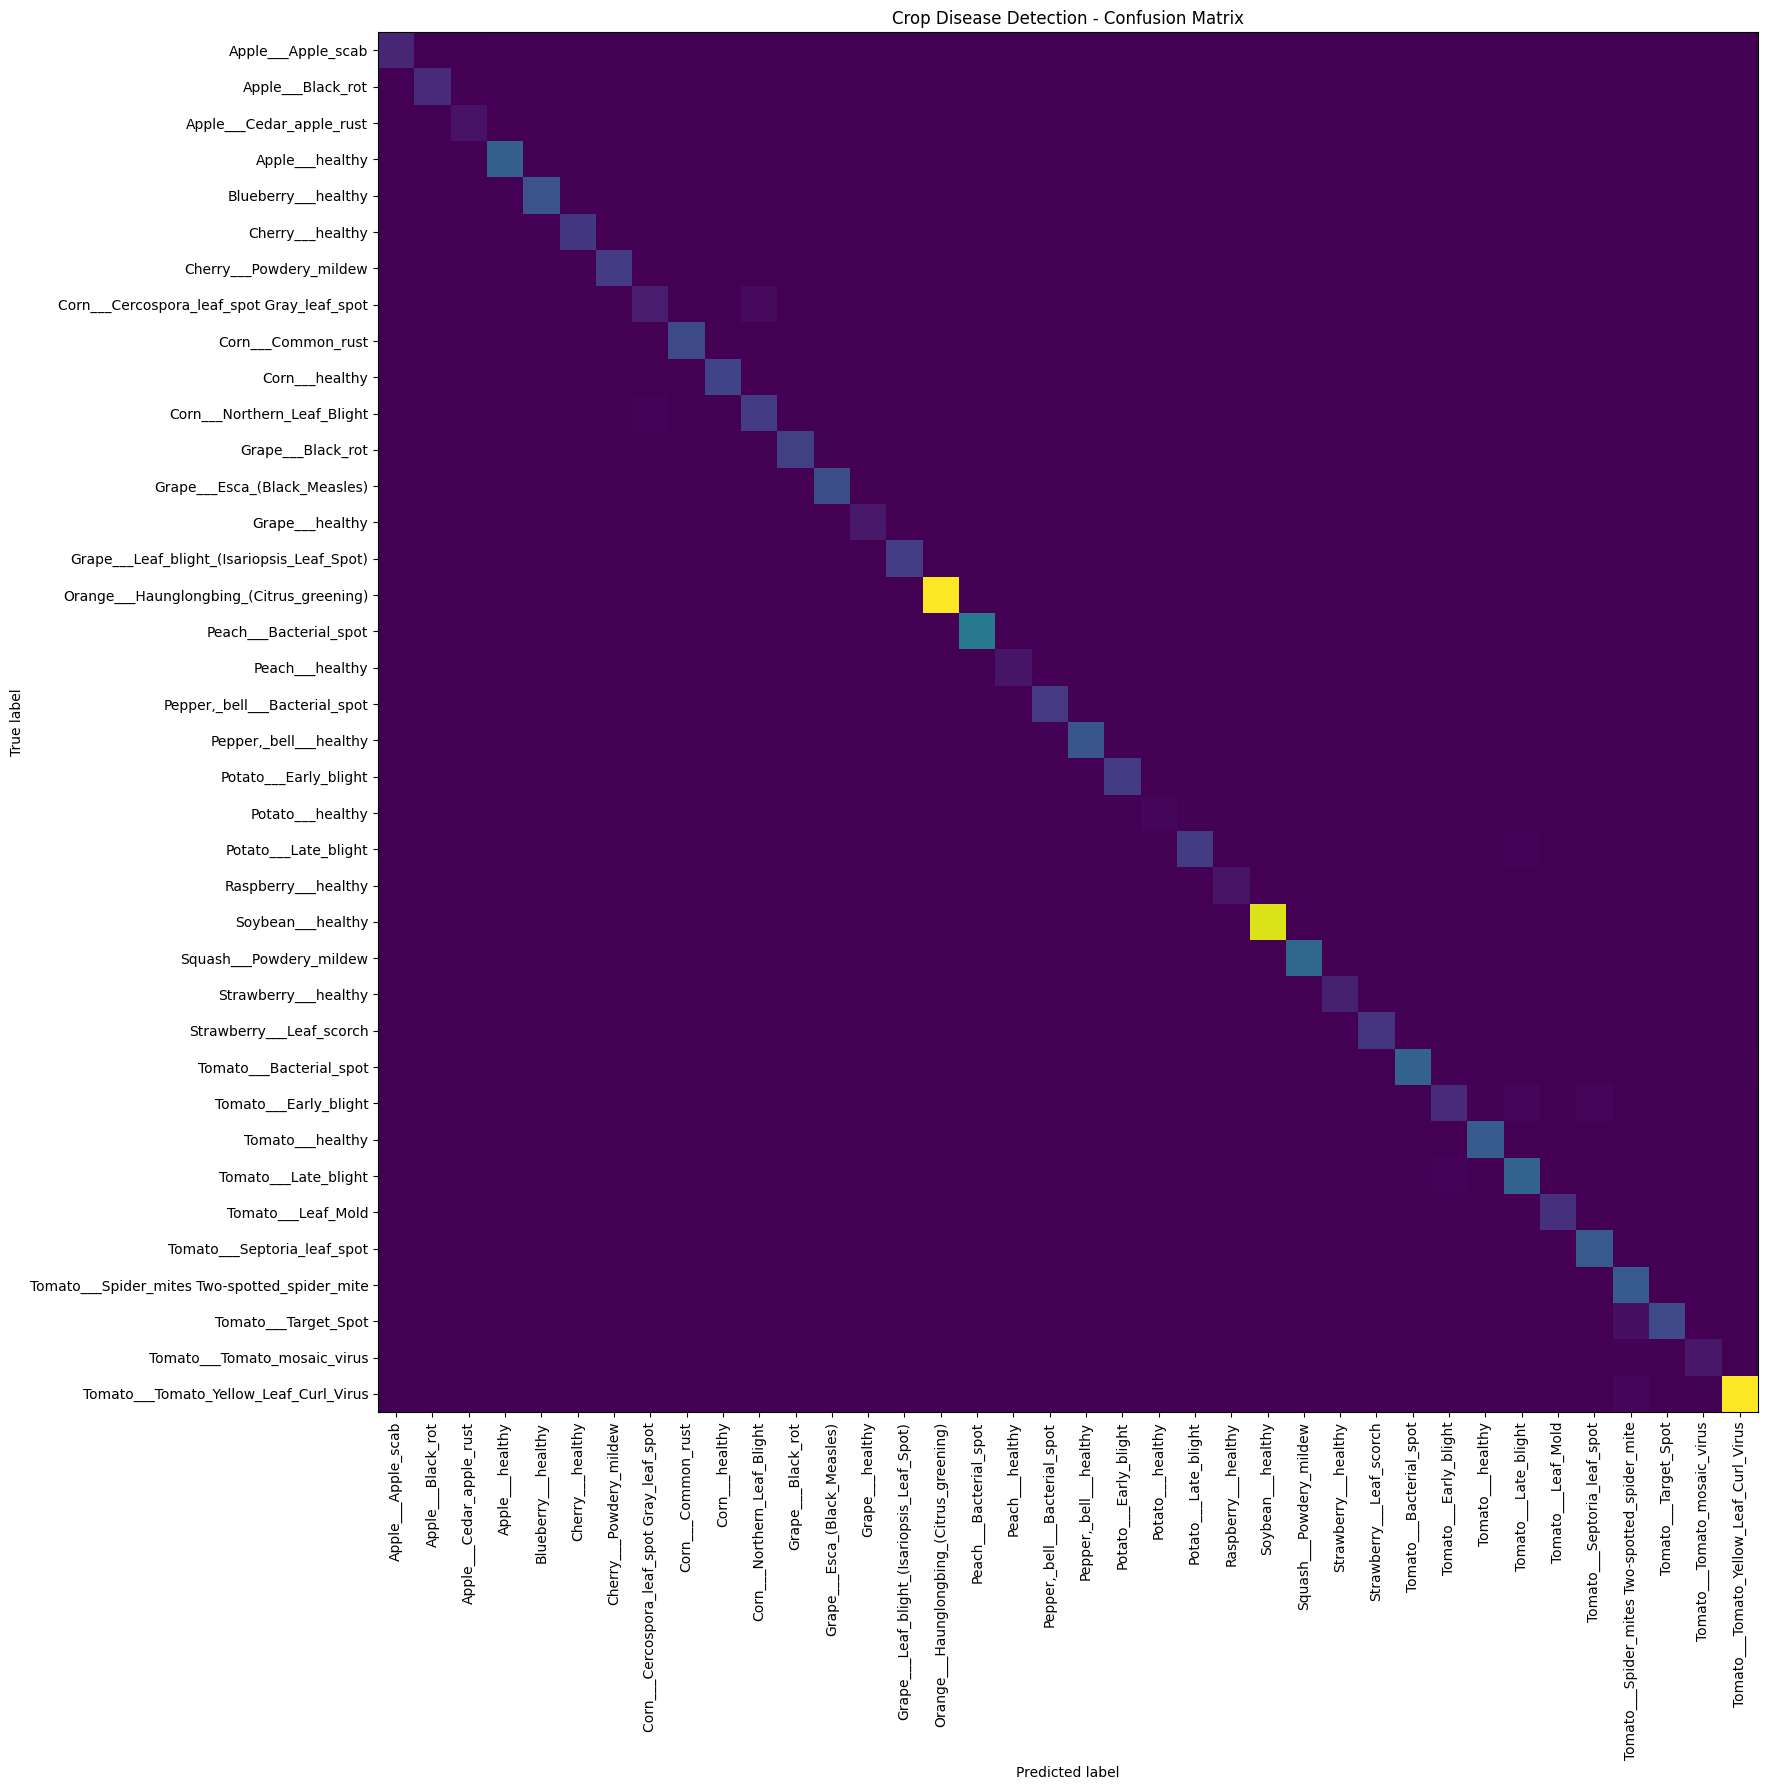

In [17]:

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_true, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

fig, ax = plt.subplots(figsize=(18, 18))
disp.plot(
    ax=ax,
    xticks_rotation="vertical",
    colorbar=False,
    include_values=False
)
plt.title("Crop Disease Detection - Confusion Matrix")
plt.tight_layout()
plt.show()


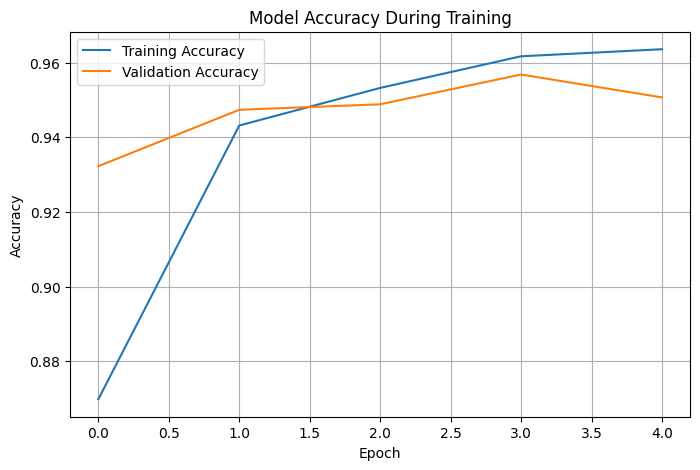

In [18]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Model Accuracy During Training")
plt.legend()
plt.grid(True)
plt.show()


Actual disease: Squash___Powdery_mildew

Top 3 predictions:
Squash___Powdery_mildew: 97.77%
Cherry___Powdery_mildew: 2.23%
Apple___Apple_scab: 0.00%


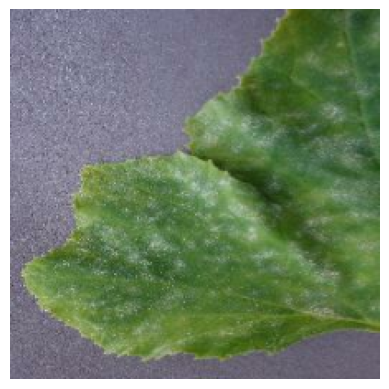

In [19]:

import numpy as np
import matplotlib.pyplot as plt

for images, labels in test_data.take(1):
    probs = model.predict(images, verbose=0)

    i = 0
    top3 = np.argsort(probs[i])[-3:][::-1]

    print("Actual disease:", class_names[labels[i].numpy()])
    print("\nTop 3 predictions:")

    for idx in top3:
        print(f"{class_names[idx]}: {probs[i][idx]*100:.2f}%")

    plt.imshow(np.clip(images[i].numpy() / 2 + 0.5, 0, 1))
    plt.axis("off")
    plt.show()


In [20]:

correct = 0
incorrect = 0

for images, labels in test_data:
    probs = model.predict(images, verbose=0)
    preds = np.argmax(probs, axis=1)
    actual = labels.numpy()

    correct += np.sum(preds == actual)
    incorrect += np.sum(preds != actual)

print("Correct predictions:", correct)
print("Incorrect predictions:", incorrect)
print("Total test images:", correct + incorrect)
print(f"Accuracy: {100*correct/(correct+incorrect):.2f}%")



Correct predictions: 7811
Incorrect predictions: 334
Total test images: 8145
Accuracy: 95.90%


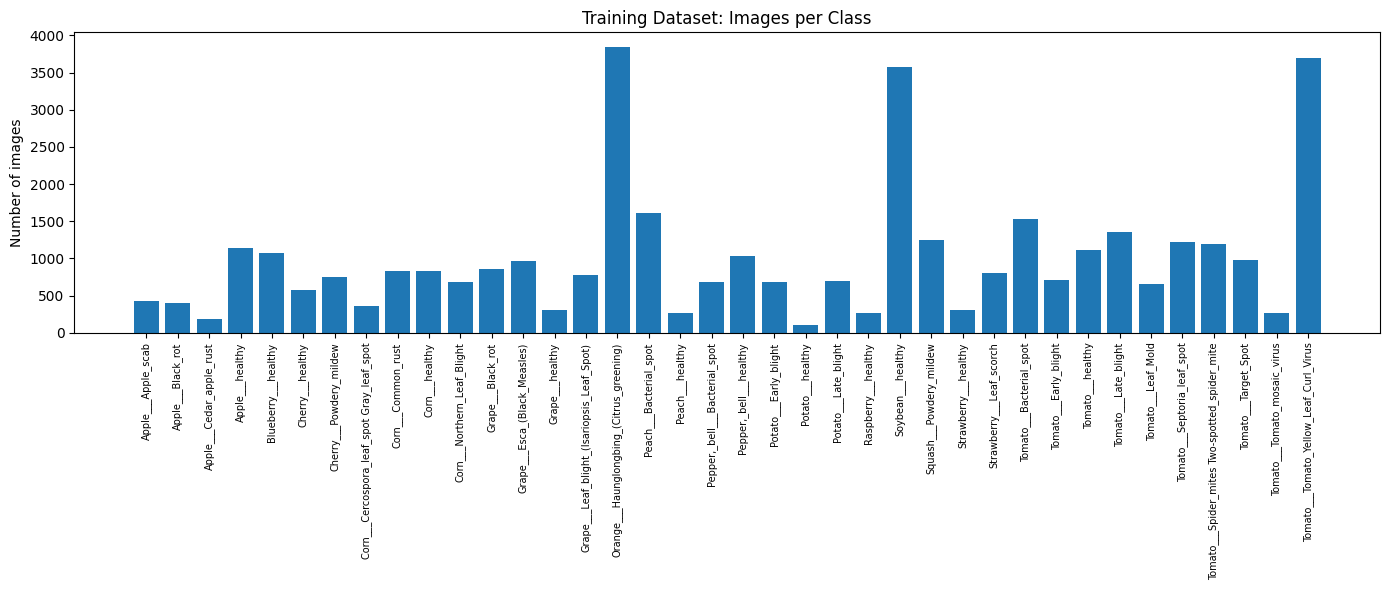

Total training images: 38012


In [21]:

from collections import Counter
import matplotlib.pyplot as plt

label_counts = Counter()

for _, label in ds_train:
    label_counts[int(label.numpy())] += 1

counts = [label_counts[i] for i in range(NUM_CLASSES)]

plt.figure(figsize=(14, 6))
plt.bar(range(NUM_CLASSES), counts)
plt.xticks(range(NUM_CLASSES), class_names, rotation=90, fontsize=7)
plt.ylabel("Number of images")
plt.title("Training Dataset: Images per Class")
plt.tight_layout()
plt.show()

print("Total training images:", sum(counts))


In [22]:

import os

model_path = "crop_disease_model.keras"

if os.path.exists(model_path):
    size_mb = os.path.getsize(model_path) / (1024 * 1024)
    print(f"Model file size: {size_mb:.2f} MB")
else:
    print("Model not saved yet. Saving now...")
    model.save(model_path)
    print("Model saved successfully!")


Model file size: 9.73 MB


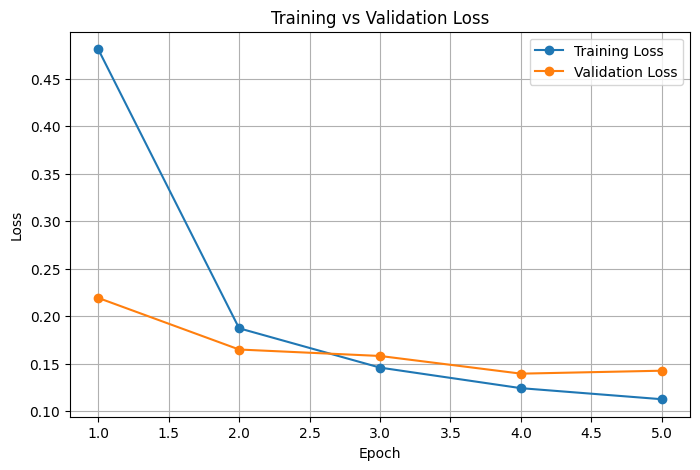

In [23]:

epochs = range(1, len(history.history["loss"]) + 1)

plt.figure(figsize=(8, 5))
plt.plot(epochs, history.history["loss"], marker="o", label="Training Loss")
plt.plot(epochs, history.history["val_loss"], marker="o", label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.legend()
plt.grid(True)
plt.show()


In [24]:

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# 1. Evaluate model on unseen test data
y_true = []
y_pred = []
y_confidence = []

for images, labels in test_data:
    probabilities = model.predict(images, verbose=0)
    predictions = np.argmax(probabilities, axis=1)
    confidence = np.max(probabilities, axis=1)

    y_true.extend(labels.numpy())
    y_pred.extend(predictions)
    y_confidence.extend(confidence)

# 2. Calculate performance metrics
accuracy = accuracy_score(y_true, y_pred)
precision = precision_score(
    y_true, y_pred, average="macro", zero_division=0
)
recall = recall_score(
    y_true, y_pred, average="macro", zero_division=0
)
f1 = f1_score(
    y_true, y_pred, average="macro", zero_division=0
)

# 3. Display final results
print("=" * 50)
print("AI-BASED CROP DISEASE DETECTION")
print("FINAL EXPERIMENTAL RESULTS")
print("=" * 50)

print(f"Model: MobileNetV2")
print(f"Dataset classes: {NUM_CLASSES}")
print(f"Test images evaluated: {len(y_true)}")
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print(f"Macro Precision: {precision * 100:.2f}%")
print(f"Macro Recall: {recall * 100:.2f}%")
print(f"Macro F1-Score: {f1 * 100:.2f}%")
print(f"Mean prediction confidence: {np.mean(y_confidence) * 100:.2f}%")

# 4. Save metrics as a CSV report
results = pd.DataFrame([{
    "Model": "MobileNetV2",
    "Number_of_Classes": NUM_CLASSES,
    "Test_Images": len(y_true),
    "Accuracy_Percent": round(accuracy * 100, 2),
    "Macro_Precision_Percent": round(precision * 100, 2),
    "Macro_Recall_Percent": round(recall * 100, 2),
    "Macro_F1_Percent": round(f1 * 100, 2),
    "Mean_Confidence_Percent": round(
        np.mean(y_confidence) * 100, 2
    )
}])

results.to_csv("crop_disease_final_results.csv", index=False)

# 5. Save detailed per-class results
report = classification_report(
    y_true,
    y_pred,
    labels=list(range(NUM_CLASSES)),
    target_names=class_names,
    zero_division=0,
    output_dict=True
)

pd.DataFrame(report).transpose().to_csv(
    "crop_disease_classification_report.csv"
)

# 6. Save the trained model
model.save("crop_disease_model.keras")

print("\nFiles created successfully:")
print("1. crop_disease_model.keras")
print("2. crop_disease_final_results.csv")
print("3. crop_disease_classification_report.csv")
print("\nProject evaluation completed!")


AI-BASED CROP DISEASE DETECTION
FINAL EXPERIMENTAL RESULTS
Model: MobileNetV2
Dataset classes: 38
Test images evaluated: 8145
Test Accuracy: 95.90%
Macro Precision: 95.52%
Macro Recall: 94.08%
Macro F1-Score: 94.57%
Mean prediction confidence: 95.19%

Files created successfully:
1. crop_disease_model.keras
2. crop_disease_final_results.csv
3. crop_disease_classification_report.csv

Project evaluation completed!
